### Conditional Flow

In [5]:
from langgraph.graph import StateGraph, END, START, state
from typing import TypedDict, Literal
from pydantic import BaseModel



In [6]:
class QuadState(TypedDict):
    a: int
    b: int
    c: int
    equation: str
    discriminant: float
    result: str

In [7]:
def show_equation(state:QuadState) -> QuadState:
    a, b, c = state['a'], state['b'], state['c']
    equation = f"{a}x^2 + {b}x + {c} = 0"

    return {"equation": equation }

def calculate_discriminant(state:QuadState) -> QuadState:
    a, b, c = state['a'], state['b'], state['c']
    discriminant = b**2 - 4*a*c

    return {"discriminant": discriminant }

def real_roots(state:QuadState) -> QuadState:
    discriminant = state['discriminant']
    root1 = (-state['b'] + discriminant**0.5) / (2*state['a'])
    root2 = (-state['b'] - discriminant**0.5) / (2*state['a'])

    return {"result": f"Roots: {root1}, {root2}" }

def  equal_roots(state:QuadState) -> QuadState:
    root = -state['b'] / (2*state['a'])

    return {"result": f"Equal Root: {root}" }

def no_real_roots(state:QuadState) -> QuadState:
    return {"result": "No Real Roots" }

In [8]:
def check_discriminant(state:QuadState) -> Literal['real_roots', 'equal_roots', 'no_real_roots']:
    discriminant = state['discriminant']
    if discriminant > 0:
        return 'real_roots'
    elif discriminant == 0:
        return 'equal_roots'
    else:
        return 'no_real_roots'

In [9]:
graph = StateGraph(QuadState)
graph.add_node("show_equation", show_equation)
graph.add_node("calculate_discriminant", calculate_discriminant)


graph.add_node("real_roots", real_roots)
graph.add_node("equal_roots", equal_roots)
graph.add_node("no_real_roots", no_real_roots)

graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calculate_discriminant")
graph.add_conditional_edges("calculate_discriminant", check_discriminant)
graph.add_edge("real_roots",END)
graph.add_edge("equal_roots", END)
graph.add_edge("no_real_roots", END)

workflow = graph.compile()

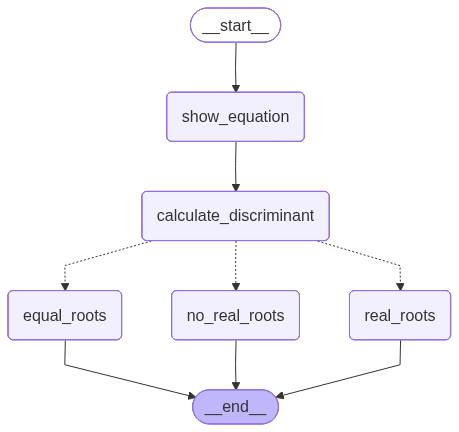

In [10]:
workflow

In [11]:
initial_states = {
'a': 1,
'b': 2,
'c': 1
}

In [12]:
workflow.invoke(initial_states)

{'a': 1,
 'b': 2,
 'c': 1,
 'equation': '1x^2 + 2x + 1 = 0',
 'discriminant': 0,
 'result': 'Equal Root: -1.0'}

## LLM Use CASE (REVIEW REPLY)

In [13]:
from langgraph.graph import StateGraph, END, START
from typing import TypedDict, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

In [14]:
load_dotenv()
model = ChatOpenAI(model='gpt-4o-mini')

In [15]:
class SentimentSchema(BaseModel):
    sentiment: Literal['positive', 'negative'] = Field(description="Sentiment of the review")

In [16]:
class DiagnosisSchema(BaseModel):
    issue_type : Literal["UX","Performance","Bug","Support","Other"] = Field(description="Category of the issue mentioned in the review")
    tone : Literal["angry","frustrated","disapointed","calm"] = Field(description="The Emotional tone Expressed by the user")
    urgency: Literal["low","medium","high"] = Field(description="How urgent or critical the issue appears to be")

structured_model1 = model.with_structured_output(SentimentSchema)
structured_model2 = model.with_structured_output(DiagnosisSchema)

In [17]:
sentence = "The app crashes every time I try to upload a photo, it's so frustrating!"
prompt=f"""What is the sentiment of the following review?"
         Review: {sentence}"""

In [18]:
structured_model1.invoke(prompt).sentiment

'negative'

In [19]:
class ReviewState(TypedDict):
    review: str
    sentiment: Literal['positive', 'negative']
    diagnosis: dict
    response: str


In [20]:
def analyze_sentiment(state: ReviewState) -> ReviewState:
    review = state['review']
    prompt = f"""What is the sentiment of the following review?"
             Review: {review}"""

    sentiment = structured_model1.invoke(prompt).sentiment
    return {"sentiment": sentiment}

In [21]:
def check_sentiment(state: ReviewState) -> Literal['positive_response', 'run_diagnosis']:
    if state['sentiment'] == 'negative':
        return 'run_diagnosis'
    else:
        return 'positive_response'


In [22]:
def positive_response(state: ReviewState) -> ReviewState:
    review = state['review']
    prompt = f"""Write a warm thank-you message in response to the following review:
{review} and also kindly ask the user to leave feedback on our website."""

    response = model.invoke(prompt).content
    return  {"response": response}



In [23]:
def run_diagnosis(state: ReviewState) -> ReviewState:
    review = state['review']
    prompt = f"""Diagnose this negative review: {review} return issue_type, tone, urgency"""
    diagnosis = structured_model2.invoke(prompt)
    return {"diagnosis": diagnosis.model_dump()}


In [24]:
def negative_response(state: ReviewState) -> ReviewState:
    review = state['review']
    diagnosis = state['diagnosis']
    prompt = f"""you are a support assistant. The user had a  {diagnosis['issue_type']} issue. The tone of the user was {diagnosis['tone']}. The urgency of the issue was {diagnosis['urgency']}. Write empathic, helpful and resolution response to the user review: {review}"""


    response = model.invoke(prompt).content
    return {"response": response}

In [25]:
graph = StateGraph(ReviewState)
graph.add_node("analyze_sentiment", analyze_sentiment)
graph.add_node("positive_response", positive_response)
graph.add_node("negative_response", negative_response)
graph.add_node("run_diagnosis", run_diagnosis)

graph.add_edge(START, "analyze_sentiment")
graph.add_conditional_edges("analyze_sentiment", check_sentiment)
graph.add_edge("positive_response", END)
graph.add_edge("run_diagnosis", "negative_response")
graph.add_edge("negative_response", END)

workflow = graph.compile()

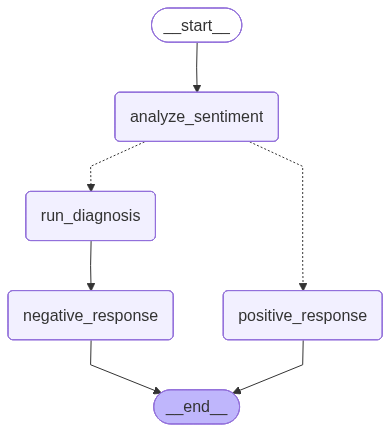

In [26]:
workflow

In [27]:
initial_states = {
    "review": "The app crashes every time I try to upload a photo, it's so frustrating!"
}

In [29]:
final_state  = workflow.invoke(initial_states)

In [32]:
final_state['review']


"The app crashes every time I try to upload a photo, it's so frustrating!"

In [31]:
final_state['sentiment']


'negative'

In [34]:
final_state['response']

"Subject: We're Here to Help!\n\nHi there,\n\nThank you for reaching out and sharing your experience with us. I completely understand how frustrating it must be to encounter crashes while trying to upload a photo, especially when you’re keen on using our app. We apologize for the inconvenience this has caused you—your time is valuable, and we want to ensure you have a smooth experience.\n\nTo help you resolve this issue as quickly as possible, could you please provide a few details? Specifically, it would be helpful to know:\n\n1. The type of device you are using (e.g., iPhone, Android)\n2. The version of the app you have installed\n3. Any specific error messages you might see before the crash\n\nIn the meantime, you might try this quick workaround: restart your app and device, and ensure you have the latest version of the app installed. Sometimes, a fresh start can help resolve unexpected issues.\n\nThank you for your patience, and we’re committed to getting this sorted out for you. I